<a href="https://colab.research.google.com/github/Maryam-Bagia/AI-Engineering/blob/main/Machine_Learning/Unsupervised_Learning/K_Means_Clustering_Simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# 1. Generate sample data (3 groups of 2D points)
np.random.seed(42)
data1 = np.random.randn(50, 2) + [2, 2]
data2 = np.random.randn(50, 2) + [8, 8]
data3 = np.random.randn(50, 2) + [2, 8]
X = np.vstack([data1, data2, data3])

In [4]:
# 2. Set K-Means parameters
K = 3
max_iters = 100

In [5]:
# 3. Pick K random points from the dataset as initial centroids
random_indices = np.random.choice(len(X), size=K, replace=False)
centroids = X[random_indices]

In [6]:
# 4. Run the K-Means Loop
for i in range(max_iters):
  # Calculate Euclidean distance from eery point to each centroid
  distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)

  # Assign each point to the closest centroid (0, 1, or 2)
  labels = np.argmin(distances, axis=1)

  # Calculate new centroids as the mean of points in each cluster
  new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])

  # Stop if centroids do not change
  if np.allclose(centroids, new_centroids):
    break

  centroids = new_centroids

In [7]:
# 5. Print results
print("Final Centroids:\n", centroids)
print("\nCluster Labels for each point:\n", labels)

Final Centroids:
 [[1.86432437 1.9279826 ]
 [2.12894675 8.00084575]
 [7.90454712 8.14006205]]

Cluster Labels for each point:
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1]


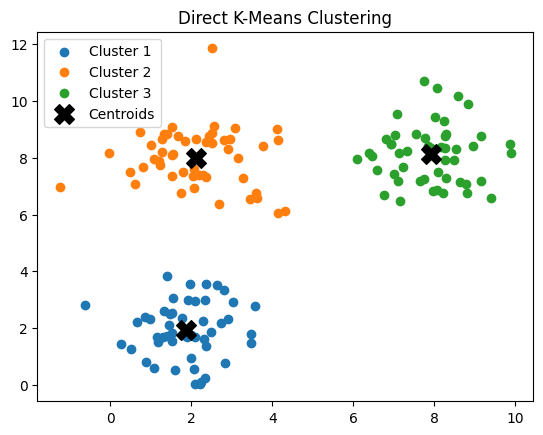

In [8]:
# 6. Plot the clusters
for k in range(K):
  plt.scatter(X[labels == k, 0], X[labels == k, 1], label=f"Cluster {k + 1}")

plt.scatter(centroids[:, 0], centroids[:, 1], color="black", marker="X", s=200, label="Centroids")
plt.title("Direct K-Means Clustering")
plt.legend()
plt.show()